# 제4장. 성진은 꿈에서 누가 되었다가 돌아왔을까? — 꿈의 흔적 읽기

[![Colab에서 열기](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ITPainter/korea-china-classics-text-mining/blob/main/notebooks/ch4_meaning.ipynb)

컴퓨터는 『구운몽』을 기쁘게 읽을까요, 슬프게 읽을까요? 꿈이라는 낱말의 분포, 16회가 『장자』에서 빌려 온 ‘나비 꿈’, 그리고 감정 점수를 함께 읽어 봅니다. 모델을 내려받으므로 처음 실행에 몇 분 걸립니다.

In [1]:
# 실습 환경 준비 (Colab에서 처음 한 번 실행)
import sys
if "google.colab" in sys.modules:
    !pip -q install "kclit @ git+https://github.com/ITPainter/korea-china-classics-text-mining.git" "gensim" "sentence-transformers"
from kclit.viz import setup_korean_font
print("그래프 글꼴:", setup_korean_font())

그래프 글꼴: AppleGothic


## 4.1 꿈이라는 낱말

먼저 ‘性真’(주인공의 본래 이름)과 ‘夢’이 회마다 몇 번 나오는지 셉니다.

In [2]:
from kclit import classics, freq
gu = classics.gu()
t = freq.term_counts(gu, ["性真", "夢"])
t.T

,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
性真,43,0,0,0,0,0,0,0,0,0,0,0,0,0,0,13
夢,0,1,1,0,4,1,2,0,1,3,1,9,6,1,0,20


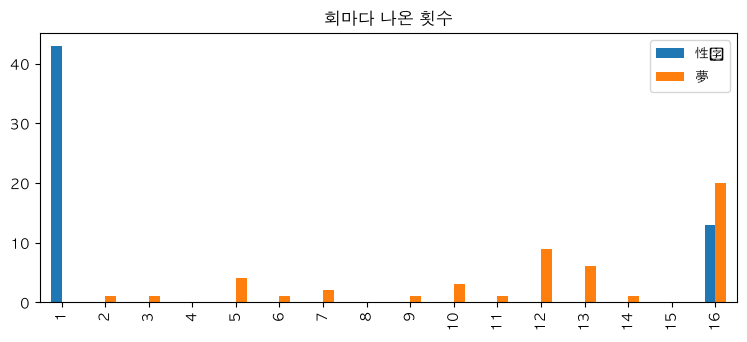

In [3]:
t.plot(kind="bar", figsize=(9, 3.5), title="회마다 나온 횟수");

‘性真’은 1회에 43번, 2~15회에는 0번, 16회에 13번입니다. ‘夢’은 마지막 16회에 20번이 몰려 있습니다. 15회 동안 성진은 양소유가 되어 꿈속을 살고 있었습니다.

### 단어 임베딩(word2vec)은 작은 코퍼스에서 어떻게 될까?

『구운몽』 한 작품(약 8만 자)으로 ‘夢’과 가까운 말을 찾아봅니다.

In [4]:
from kclit import embed, text, tokenize
sents = [s for c in gu for s in text.split_sentences(c) if len(s) >= 6]
w2v = embed.train_word2vec([tokenize.chinese(s) for s in sents], vector_size=50, min_count=3)
embed.neighbors(w2v, "夢", topn=8)

[('非', 0.997),
 ('日', 0.997),
 ('更', 0.997),
 ('無', 0.997),
 ('於', 0.997),
 ('且', 0.997),
 ('是', 0.997),
 ('既', 0.997)]

**AI가 틀린 순간:** 이웃 단어가 ‘非’, ‘日’, ‘更’처럼 어디에나 쓰이는 말뿐이고 유사도는 전부 0.99입니다. 한 작품만으로는 임베딩이 불안정합니다. 큰 코퍼스가 필요합니다.

### 다국어 문장 검색

이번에는 한국어 질문과 가장 뜻이 가까운 한문 문장을 찾습니다. 한국어와 중국어를 같은 공간에 놓는 다국어 모델을 씁니다.

In [5]:
model = embed.sentence_model()
vectors = embed.encode(model, sents)
def search(question, k=3):
    sim = embed.cosine_matrix(embed.encode(model, [question]), vectors)[0]
    for i in sim.argsort()[::-1][:k]:
        print(f"  {sim[i]:.2f} {sents[i][:60]}")
for q in ["꿈에서 깨어났다", "공주와 혼인했다"]:
    print(q); search(q)

꿈에서 깨어났다
  0.73 孰知何事之爲夢，何事之爲真耶？
  0.72 丞相心不勝癢，始乃發笑曰：「吾與夫人只卜後生之相逢矣，今日我在夢中，而亦不知夢耶？
  0.69 蝴蝶z夢爲莊周耶？
공주와 혼인했다
  0.77 與公主同覽其祝文曰：
  0.74 必公主欲見而招來也。
  0.71 聞相公娶兩公主爲女君，未知兩位公主能容妾等否？


‘꿈에서 깨어났다’로 물으면 ‘孰知何事之爲夢，何事之爲真耶’(무엇이 꿈이고 무엇이 참인지 누가 알겠느냐)처럼 16회의 깨달음 대목이 위에 올라옵니다. 고전 한문은 모델이 덜 배운 글이라 질문에 따라 엉뚱한 문장이 나올 수도 있으니 결과를 꼭 읽어 보세요.

## 4.2 장주의 나비 꿈

**궁금한 점:** ‘夢’이 가장 몰려 있는 16회는 꿈 이야기를 어디서 빌려 왔을까요? 16회에는 ‘莊周’가 나옵니다. 먼저 어디에 몇 번 나오는지 셉니다.

In [6]:
from kclit import reuse
freq.term_counts(gu, ["莊周", "蝴蝶"]).T

,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
莊周,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,4
蝴蝶,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,4


‘莊周’ 4번은 모두 16회에 있습니다. ‘蝴蝶’ 5번 가운데 1번은 12회인데 꿈속 풍경에 나오는 나비일 뿐입니다. 이제 『장자』 「齊物論」과 비교해 인용 후보를 찾습니다.

In [7]:
zhuangzi = text.split_sentences(classics.qiwulun())
targets = {f"구운몽 {n}회": text.split_sentences(c) for n, c in enumerate(gu, 1)}
found = reuse.to_frame(reuse.find_reuse(targets, {"莊子·齊物論": zhuangzi}, n=2, min_score=0.15, min_shared=4))
found[["target_id", "target_line", "source_line", "score", "shared"]]

,target_id,target_line,source_line,score,shared
0,구운몽 16회,莊周之夢爲蝴蝶耶？,不知周之夢爲胡蝶與？,0.250,周之夢為
1,구운몽 4회,生乍對曰：「貧道傳得於師，而不知其曲名，故正待小姐之命矣。,已而不知其然謂之道。,0.107,而不知其
2,구운몽 16회,莊周夢爲蝴蝶，蝴蝶又變爲莊周。,昔者莊周夢爲胡蝶，栩栩然胡蝶也，自喻適志與，不知周也。,0.107,莊周夢為
3,구운몽 4회,生乍對曰：「貧道傳得於師，而不知其曲名，故正待小姐之命矣。,勞神明爲一，而不知其同也，謂之朝三。,0.088,而不知其
4,구운몽 4회,生乍對曰：「貧道傳得於師，而不知其曲名，故正待小姐之命矣。,注焉而不滿，酌焉而不竭，而不知其所由來，此之謂葆光。,0.079,而不知其
5,구운몽 4회,生乍對曰：「貧道傳得於師，而不知其曲名，故正待小姐之命矣。,非彼无我，非我无所取，是亦近矣，而不知其所爲使。,0.077,而不知其
6,구운몽 4회,生乍對曰：「貧道傳得於師，而不知其曲名，故正待小姐之命矣。,終身役役，而不見其成功，薾一作「𦬼」然疲役，而不知其所歸，可不哀邪？,0.070,而不知其
7,구운몽 16회,莊周之夢爲蝴蝶耶？,胡蝶之夢爲周與？,0.182,之夢為
8,구운몽 12회,』賈女之謂也。,其留如詛盟，其守勝之謂也。,0.167,之謂也
9,구운몽 6회,不知其方在何山矣。,已而不知其然謂之道。,0.154,不知其


16회의 두 문장이 후보로 올라옵니다. 『장자』는 ‘胡蝶’, 『구운몽』은 ‘蝴蝶’로 적어서 글자는 다르지만 ‘莊周夢爲’, ‘周之夢爲’가 겹칩니다. 4회의 ‘而不知其’는 어디에나 쓰이는 표현이 우연히 겹친 **우연한 일치**입니다. 후보는 ‘확정된 인용’이 아니라 ‘읽어 볼 후보’입니다.

In [8]:
# 기준을 더 엄격하게 하면 어떻게 될까?
reuse.to_frame(reuse.find_reuse(targets, {"莊子·齊物論": zhuangzi}, n=2, min_score=0.15, min_shared=6))

,target_id,target_line,source_id,source_line,score,shared
0,구운몽 16회,莊周之夢爲蝴蝶耶？,莊子·齊物論,不知周之夢爲胡蝶與？,0.250,周之夢為
1,구운몽 16회,莊周之夢爲蝴蝶耶？,莊子·齊物論,胡蝶之夢爲周與？,0.182,之夢為
2,구운몽 12회,』賈女之謂也。,莊子·齊物論,其留如詛盟，其守勝之謂也。,0.167,之謂也
3,구운몽 6회,不知其方在何山矣。,莊子·齊物論,已而不知其然謂之道。,0.154,不知其
4,구운몽 12회,』賈女之謂也。,莊子·齊物論,其發若機栝，其司是非之謂也。,0.154,之謂也
5,구운몽 13회,故丞相不知其來矣。,莊子·齊物論,已而不知其然謂之道。,0.154,不知其
6,구운몽 15회,驕侏自恣之罪，不可不懲。,莊子·齊物論,可乎可，不可乎不可。,0.167,不可


## 4.3 감정 읽기

쇼핑 리뷰로 학습한 중국어 감성분석 모델에 『구운몽』을 넣습니다. 3,000여 문장이라 몇 분 걸립니다.

In [9]:
import numpy as np
from kclit import sentiment
per_chapter = []
for c in gu:
    s = [x for x in text.split_sentences(c) if len(x) >= 4]
    per_chapter.append((s, sentiment.score(s, "zh")))
all_scores = [v for _, sc in per_chapter for v in sc]
print("문장 수:", len(all_scores))
print("평균:", round(float(np.mean(all_scores)), 2), "| 부정 문장 비율:", round(sum(v < 0 for v in all_scores) / len(all_scores), 2))

문장 수: 3450
평균: 0.8 | 부정 문장 비율: 0.06


In [10]:
import pandas as pd
table = pd.DataFrame({
    "평균": [round(float(np.mean(sc)), 2) for _, sc in per_chapter],
    "부정 비율": [round(sum(v < 0 for v in sc) / len(sc), 2) for _, sc in per_chapter],
}, index=range(1, 17))
table.T

,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
평균,0.79,0.76,0.84,0.78,0.80,0.79,0.88,0.78,0.76,0.80,0.81,0.82,0.81,0.83,0.80,0.80
부정 비율,0.06,0.09,0.05,0.08,0.07,0.08,0.02,0.07,0.08,0.07,0.06,0.05,0.05,0.05,0.06,0.07


Text(0.5, 0, '회')

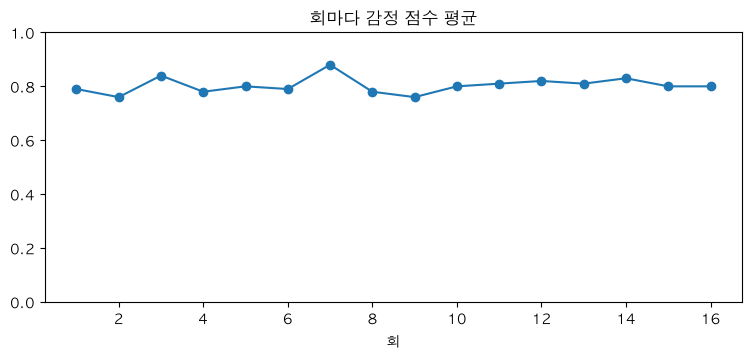

In [11]:
import matplotlib.pyplot as plt
ax = table["평균"].plot(marker="o", figsize=(9, 3.5), ylim=(0, 1), title="회마다 감정 점수 평균")
ax.set_xlabel("회")

**AI가 틀린 순간:** 곡선이 거의 평평합니다. 인생무상을 깨닫는 이야기가 처음부터 끝까지 ‘기쁜 이야기’로 읽혔습니다. 모델의 점수는 ‘진짜 정서’가 아니라 ‘모델이 학습한 글의 정서’입니다.

In [12]:
# 성진이 깨달음을 말하는 대목은 몇 점일까?
sentences, scores = per_chapter[15]
for s, v in zip(sentences, scores):
    if "喚起一夜之夢" in s:
        print(f"{v:+.2f}  {s[:70]}")

+0.99  而師父喚起一夜之夢，能悟性真之心，師父大恩，雖閱讀千萬塵劫，而不可報也。


점수는 평평한데 낱말의 분포(‘性真’, ‘夢’)는 작품의 전환점을 분명히 보여 줍니다. 그래서 모델의 점수는 최종 답이 아니라 읽을 곳을 정하는 참고 자료로 씁니다.